# S0 Development Modeling and Model Selection

Part 2 compares opening-price regressors and positive-listing-gain classifiers.
Only the fixed development population is supplied to fitting/scoring. The 2025
reserved set is not predicted or scored here. Re-running this notebook repeats
the same prespecified search; it does not authorize additional tuning.

The four 2024 folds contain 90 unique validation IPOs and training sizes of
59, 80, 94 and 121. Outcomes must be available before each fit cutoff.
Earlier data preparation exposed aggregate full-cohort outcomes, so the reserved
period is not claimed as completely unseen external data.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "config/evaluation.json").exists() and (p / "ipo_prediction").is_dir())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from ipo_prediction.train import run, development_inputs
from ipo_prediction.data import feature_names, get_xy
from ipo_prediction.models import positive_probability
plan = json.loads((root / "config/model_search.json").read_text())
print("Fixed classification threshold:", plan["classification_threshold"])
print("Selection uses pooled validation MAE for price and accuracy for classification.")
print("No reserved-period outcomes are scored.")

Fixed classification threshold: 0.5
Selection uses pooled validation MAE for price and accuracy for classification.
No reserved-period outcomes are scored.


## 1. Prespecified comparisons and leakage controls

Ten regression candidates: announced cap, a training-only median-premium
baseline, Ridge with two alpha values, and Random Forest with two restrained
settings. Learned families each compare 12 core predictors against a 19-variable
financial extension. Nine classification candidates: always Apply, logistic
regression with/without balanced weights and two Random Forest settings, again
comparing both feature sets. Settings are recorded in `config/model_search.json`.

The premium baseline predicts announced cap × median(training opening price /
training announced cap), never using a future final issue price. Learned prices
have a prespecified physical floor of INR 0.01. All learned preprocessing is
inside the fitted model pipeline. Extra outcome/subscription inputs are rejected.

Threshold 0.5 was fixed before comparisons. Regression ranking uses pooled MAE,
then RMSE and simplicity. Classification uses pooled accuracy, then balanced
accuracy, Brier score and simplicity. Baselines can win. These selection metrics
are not unbiased final performance estimates.

In [2]:
summary = run()
out = root / "outputs/part2"
registry = json.loads((out / "candidate_registry.json").read_text())
display(pd.DataFrame(registry)[["candidate_id", "task", "feature_set", "params"]])
display(pd.Series(summary, name="Part 2 completion").to_frame())

Validated regression_announced_cap_core_baseline


Validated regression_training_median_premium_core_baseline


Validated classification_always_apply_core_baseline


Validated regression_ridge_core_alpha1


Validated regression_ridge_core_alpha100


...

Validated classification_random_forest_extended_setting1


Validated classification_random_forest_extended_setting2


{
  "part": 2,
  "status": "complete",
  "development_IPOs": 149,
  "validation_IPOs": 90,
  "regression_candidates": 10,
  "classification_candidates": 9,
  "fold_fits": 76,
  "selected_regression": "regression_training_median_premium_core_baseline",
  "selected_classification": "classification_random_forest_core_setting1",
  "validation_regression_mae_inr": 94.45002293960916,
  "validation_classification_accuracy": 0.7777777777777778,
  "saved_development_models": 12,
  "figures": [
    "01_regression_comparison.png",
    "02_classification_comparison.png",
    "03_fold_stability.png",
    "04_selected_price_diagnostics.png",
    "05_selected_classification_diagnostics.png"
  ],
  "checks_passed": 11,
  "reserved_outcome_metrics_computed": false,
  "final_models_fitted": false,
  "selection_scores_are_final_performance": false
}


,candidate_id,task,feature_set,params
0,regression_announced_cap_core_baseline,regression,core,{}
1,regression_training_median_premium_core_baseline,regression,core,{}
2,classification_always_apply_core_baseline,classification,core,{}
3,regression_ridge_core_alpha1,regression,core,{'alpha': 1.0}
4,regression_ridge_core_alpha100,regression,core,{'alpha': 100.0}
5,regression_random_forest_core_setting1,regression,core,"{'n_estimators': 200, 'max_depth': 3, 'min_sam..."
6,regression_random_forest_core_setting2,regression,core,"{'n_estimators': 200, 'max_depth': 5, 'min_sam..."
7,classification_logistic_core_setting1,classification,core,"{'C': 1.0, 'class_weight': None}"
8,classification_logistic_core_setting2,classification,core,"{'C': 1.0, 'class_weight': 'balanced'}"
9,classification_random_forest_core_setting1,classification,core,"{'n_estimators': 200, 'max_depth': 3, 'min_sam..."


,Part 2 completion
part,2
status,complete
development_IPOs,149
validation_IPOs,90
regression_candidates,10
classification_candidates,9
fold_fits,76
selected_regression,regression_training_median_premium_core_baseline
selected_classification,classification_random_forest_core_setting1
validation_regression_mae_inr,94.450023


## 2. Opening-price regression

MAE and RMSE are measured in rupees; MAPE is a percentage error, not model
accuracy. Absolute rupee loss weights high-priced IPO mistakes more strongly.
Read MAPE and the quarter results alongside the primary MAE ranking.

,rank,candidate_id,feature_set,mae_inr,rmse_inr,mape_pct,n
0,1,regression_training_median_premium_core_baseline,core,94.450,158.020,17.974,90
1,2,regression_announced_cap_core_baseline,core,108.479,197.259,19.527,90
2,3,regression_random_forest_core_setting1,core,122.811,225.862,25.004,90
3,4,regression_random_forest_extended_setting1,extended,122.824,225.753,25.013,90
4,5,regression_ridge_core_alpha1,core,126.002,177.408,35.298,90
5,6,regression_random_forest_extended_setting2,extended,142.494,265.316,29.314,90
6,7,regression_random_forest_core_setting2,core,142.497,265.315,29.310,90
7,8,regression_ridge_extended_alpha1,extended,150.991,233.938,45.562,90
8,9,regression_ridge_core_alpha100,core,168.035,249.130,64.448,90
9,10,regression_ridge_extended_alpha100,extended,174.696,252.736,69.984,90


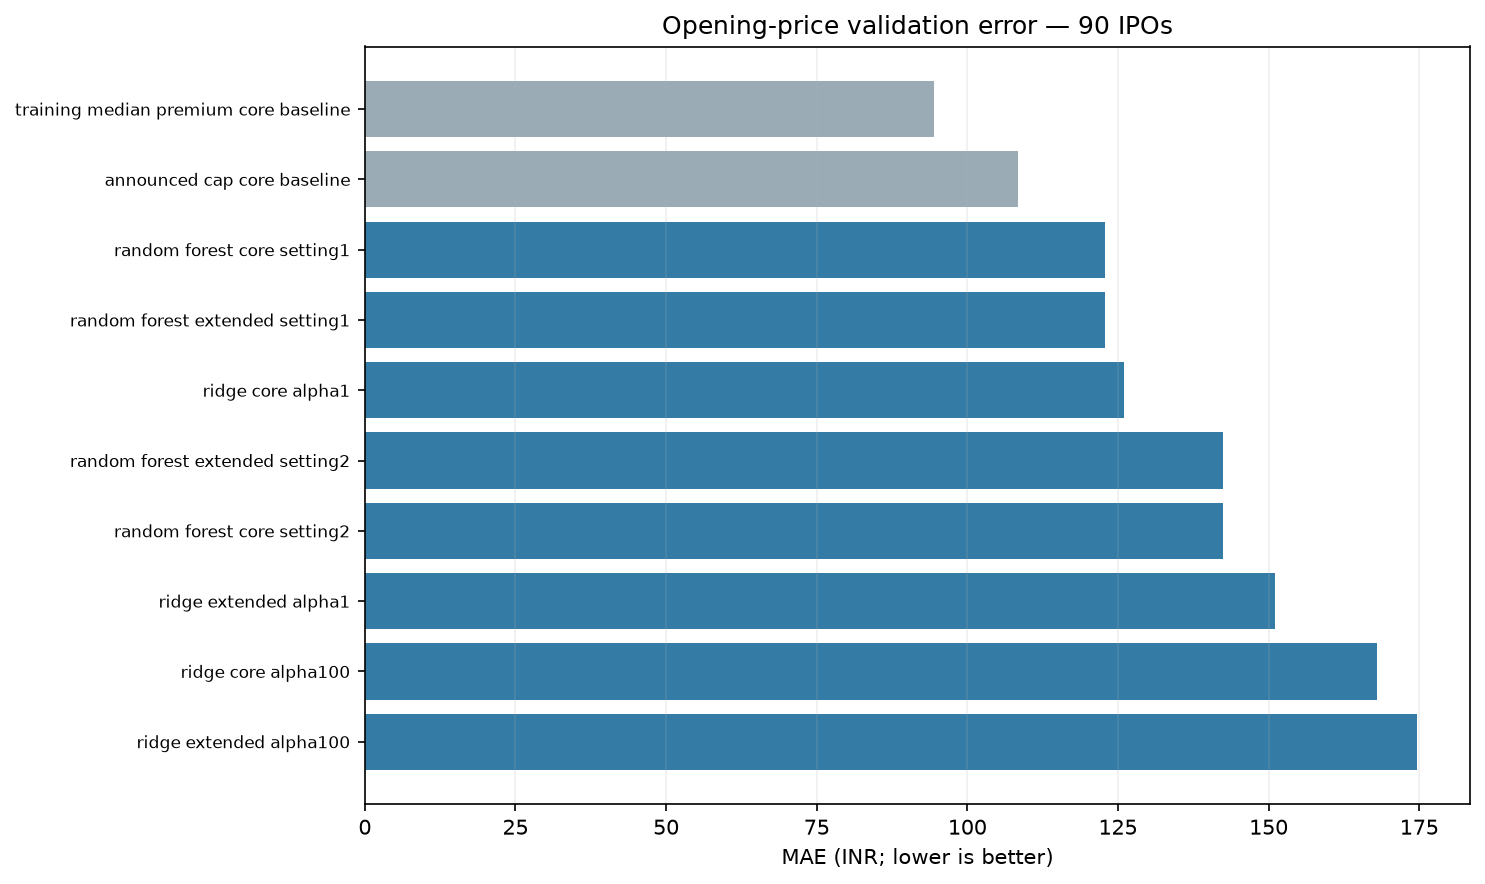

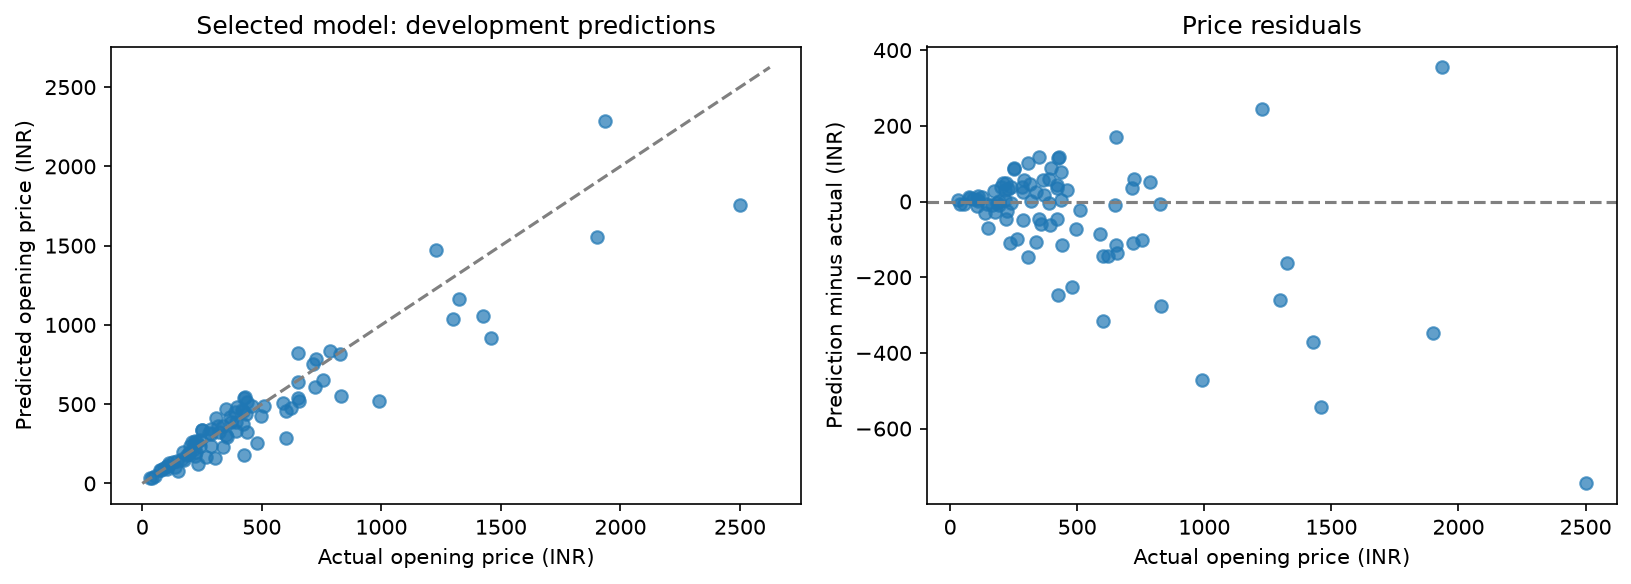

In [3]:
regression = pd.read_csv(out / "regression_comparison.csv")
display(regression[["rank", "candidate_id", "feature_set", "mae_inr", "rmse_inr", "mape_pct", "n"]].round(3))
display(Image(filename=str(root / "figures/part2/01_regression_comparison.png")))
display(Image(filename=str(root / "figures/part2/04_selected_price_diagnostics.png")))

## 3. Positive-gain classification

Apply means predicted opening price exceeds final issue price, before costs and
without modeling allotment. A model can match the majority baseline while
identifying no losing listings. Therefore include balanced accuracy, Skip
specificity and full confusion counts alongside accuracy. Raw class probabilities
are not calibrated investment confidence estimates.

,rank,candidate_id,accuracy,balanced_accuracy,precision_apply,recall_apply,f1_apply,specificity_skip,brier,tn,fp,fn,tp
0,1,classification_random_forest_core_setting1,0.7778,0.5000,0.7778,1.0000,0.8750,0.00,0.1836,0.0,20.0,0.0,70.0
1,2,classification_random_forest_extended_setting1,0.7778,0.5000,0.7778,1.0000,0.8750,0.00,0.1849,0.0,20.0,0.0,70.0
2,3,classification_always_apply_core_baseline,0.7778,0.5000,0.7778,1.0000,0.8750,0.00,0.2222,0.0,20.0,0.0,70.0
3,4,classification_logistic_core_setting1,0.7111,0.4929,0.7750,0.8857,0.8267,0.10,0.2189,2.0,18.0,8.0,62.0
4,5,classification_logistic_extended_setting1,0.6667,0.5000,0.7778,0.8000,0.7887,0.20,0.2524,4.0,16.0,14.0,56.0
5,6,classification_random_forest_core_setting2,0.6444,0.6107,0.8393,0.6714,0.7460,0.55,0.2387,11.0,9.0,23.0,47.0
6,7,classification_random_forest_extended_setting2,0.5556,0.4464,0.7500,0.6429,0.6923,0.25,0.2359,5.0,15.0,25.0,45.0
7,8,classification_logistic_extended_setting2,0.5222,0.5143,0.7872,0.5286,0.6325,0.50,0.3282,10.0,10.0,33.0,37.0
8,9,classification_logistic_core_setting2,0.4222,0.4679,0.7500,0.3857,0.5094,0.55,0.3181,11.0,9.0,43.0,27.0


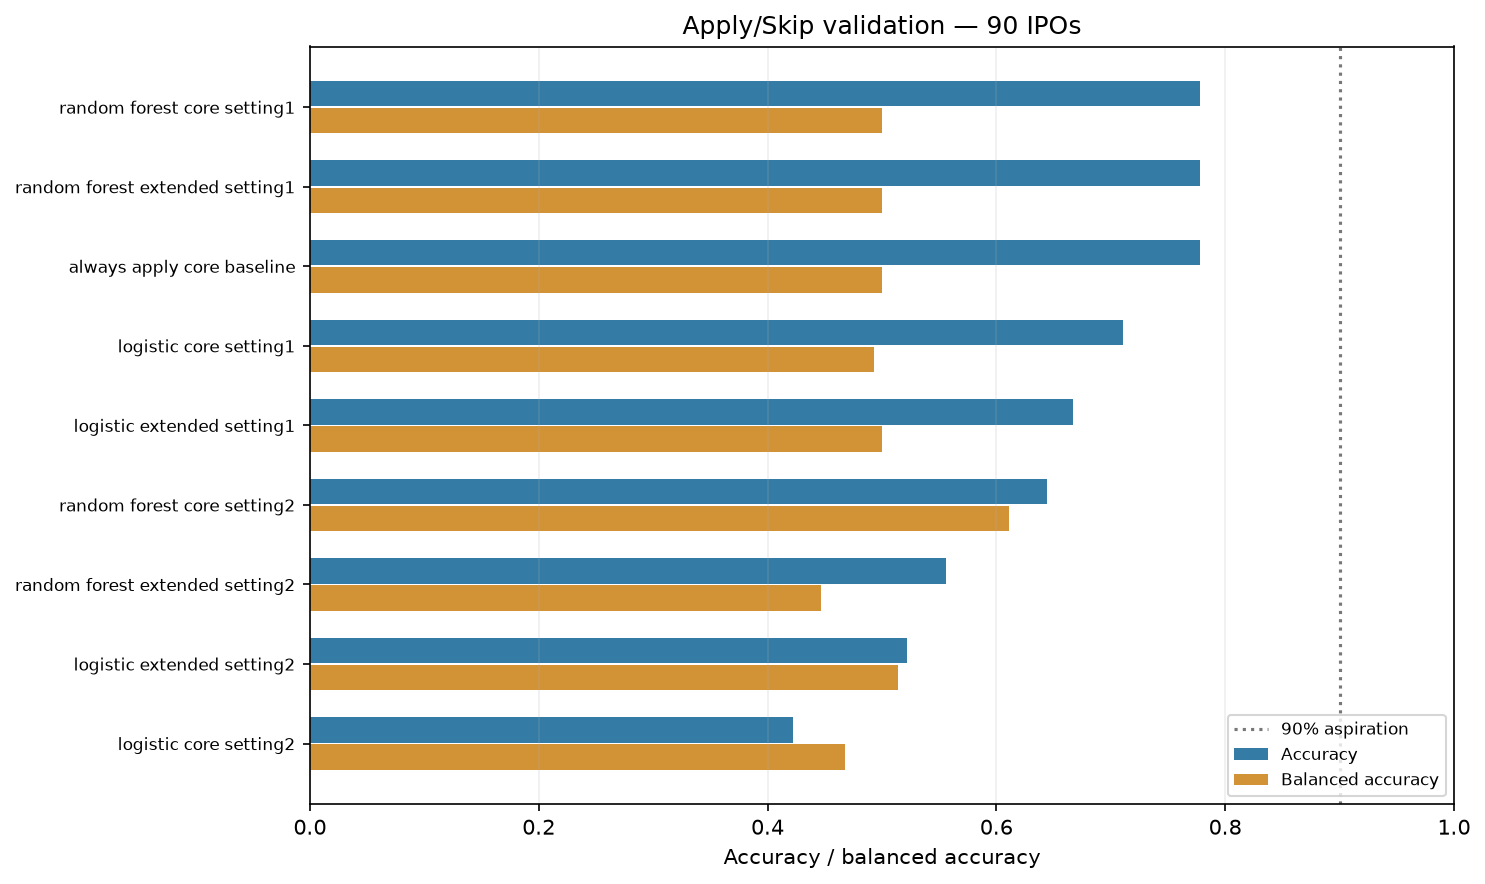

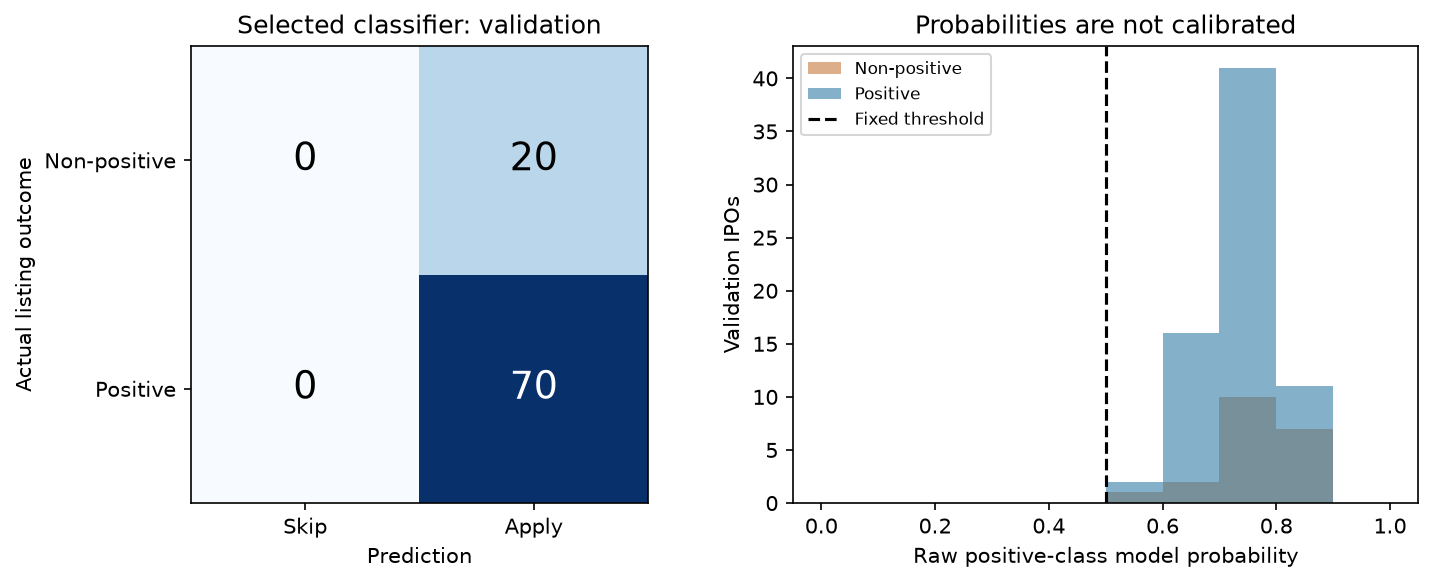

**Selected validation accuracy: 77.78%; always-Apply baseline: 77.78%.**

**The selected classifier predicts Apply for every validation IPO. It has not demonstrated a useful Apply/Skip distinction.**

The 90% accuracy aspiration was not reached in development validation.


In [4]:
classification = pd.read_csv(out / "classification_comparison.csv")
display(classification[["rank", "candidate_id", "accuracy", "balanced_accuracy", "precision_apply", "recall_apply", "f1_apply", "specificity_skip", "brier", "tn", "fp", "fn", "tp"]].round(4))
display(Image(filename=str(root / "figures/part2/02_classification_comparison.png")))
display(Image(filename=str(root / "figures/part2/05_selected_classification_diagnostics.png")))
chosen = classification.iloc[0]
baseline = classification.loc[classification.is_baseline].iloc[0]
display(Markdown(f"**Selected validation accuracy: {chosen.accuracy:.2%}; always-Apply baseline: {baseline.accuracy:.2%}.**"))
if int(chosen.predicted_skip) == 0:
    display(Markdown("**The selected classifier predicts Apply for every validation IPO. It has not demonstrated a useful Apply/Skip distinction.**"))
if chosen.accuracy < .9:
    print("The 90% accuracy aspiration was not reached in development validation.")

## 4. Quarter stability and comparison limits

Each IPO appears in validation once, and each quarter uses a fresh model with
earlier mature training labels. Pooled ranking weights each validation IPO
equally. Quarterly scores show instability but are not extra independent tests;
one quarter contains only one non-positive listing.

,candidate_id,task,fold_id,mae_inr,rmse_inr,mape_pct,n,accuracy,balanced_accuracy,precision_apply,recall_apply,f1_apply,specificity_skip,brier,tn,fp,fn,tp,predicted_apply,predicted_skip
4,regression_training_median_premium_core_baseline,regression,2024_Q1,71.1253,98.6082,20.3672,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,regression_training_median_premium_core_baseline,regression,2024_Q2,76.0383,121.9427,13.7570,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,regression_training_median_premium_core_baseline,regression,2024_Q3,87.7284,139.4711,17.7828,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,regression_training_median_premium_core_baseline,regression,2024_Q4,128.2239,217.0803,18.3798,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36,classification_random_forest_core_setting1,classification,2024_Q1,NaN,NaN,NaN,22,0.6364,0.5,0.6364,1.0,0.7778,0.0,0.2634,0.0,8.0,0.0,14.0,22.0,0.0
37,classification_random_forest_core_setting1,classification,2024_Q2,NaN,NaN,NaN,14,0.9286,0.5,0.9286,1.0,0.9630,0.0,0.1332,0.0,1.0,0.0,13.0,14.0,0.0
38,classification_random_forest_core_setting1,classification,2024_Q3,NaN,NaN,NaN,26,0.8462,0.5,0.8462,1.0,0.9167,0.0,0.1318,0.0,4.0,0.0,22.0,26.0,0.0
39,classification_random_forest_core_setting1,classification,2024_Q4,NaN,NaN,NaN,28,0.7500,0.5,0.7500,1.0,0.8571,0.0,0.1940,0.0,7.0,0.0,21.0,28.0,0.0


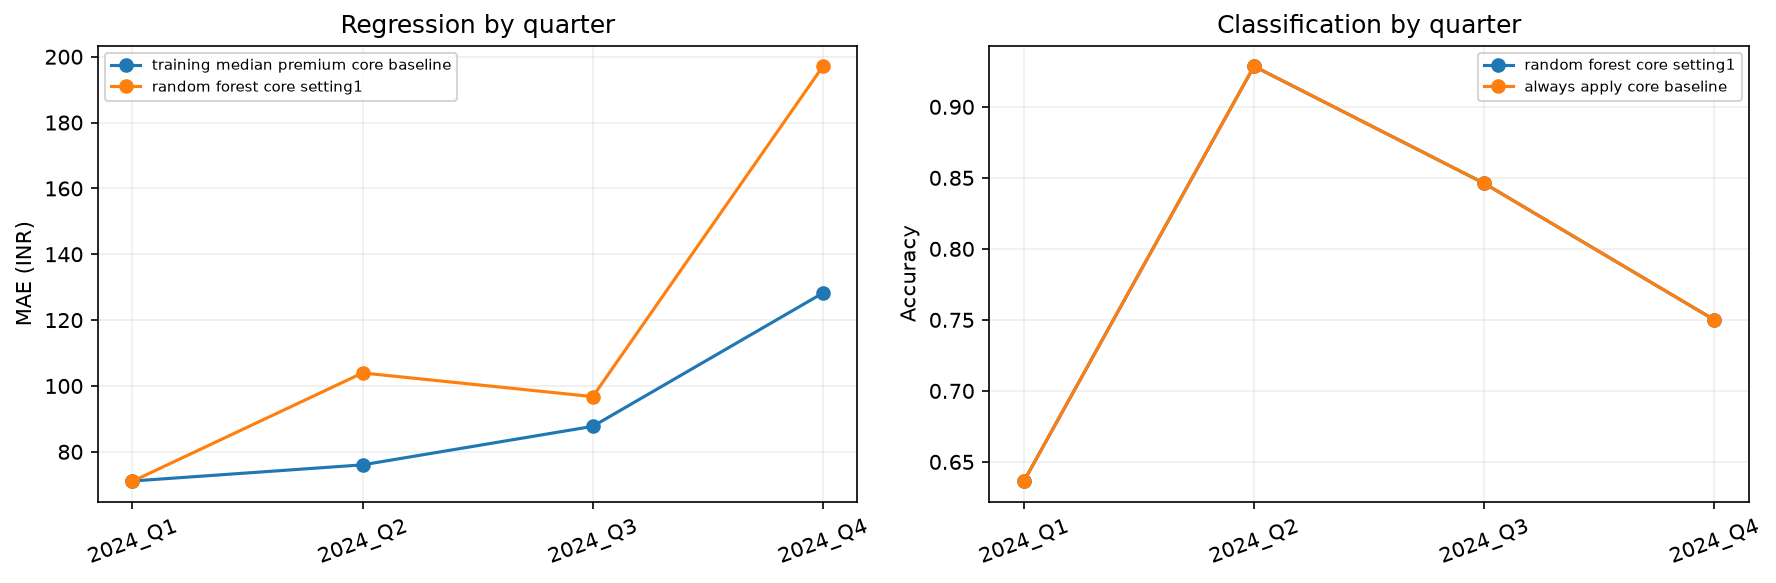

In [5]:
folds = pd.read_csv(out / "fold_metrics.csv")
selected = json.loads((root / "config/selected_models.json").read_text())
selected_ids = [selected["selection"][task]["candidate_id"] for task in ["regression", "classification"]]
display(folds.loc[folds.candidate_id.isin(selected_ids)].dropna(axis=1, how="all").round(4))
display(Image(filename=str(root / "figures/part2/03_fold_stability.png")))

## 5. Audits and representative mistakes

Audit every fit rather than assuming time order from row order. Review large
price errors and incorrect classifications without dropping or relabeling them.
These errors remain part of validation. The source datasets are unchanged.

In [6]:
audit = pd.read_csv(out / "training_audit.csv")
display(audit.groupby("fold_id")[["training_IPOs", "validation_IPOs", "reserved_rows_used"]].first())
display(pd.read_csv(out / "validation_checks.csv"))
display(pd.read_csv(out / "largest_price_errors.csv").head(5))
display(pd.read_csv(out / "classification_errors.csv").head(5))

,training_IPOs,validation_IPOs,reserved_rows_used
fold_id,,,
2024_Q1,59,22,0
2024_Q2,80,14,0
2024_Q3,94,26,0
2024_Q4,121,28,0


,check,passed
0,bundled source data unchanged,True
1,only 149 development rows supplied to modeling,True
2,same 90 development validation IPOs for every ...,True
3,all 19 prespecified candidates evaluated,True
4,all 76 candidate/fold fits audited,True
5,training labels mature before fold cutoff,True
6,reserved rows not used for fitting or scoring,True
7,no training convergence warnings,True
8,saved fold models reproduce validation predict...,True
9,model choices and threshold frozen,True


,candidate_id,task,fold_id,ipo_id,company_name,s0_cutoff_at,fit_cutoff,actual,prediction,absolute_error_inr,predicted_class
0,regression_training_median_premium_core_baseline,regression,2024_Q4,waaree-energies-f5c224,Waaree Energies Limited,2024-10-21 09:00:00+05:30,2024-10-08 09:00:00+05:30,2500.0,1755.000000,745.000000,NaN
1,regression_training_median_premium_core_baseline,regression,2024_Q4,unimech-aerospace-manufacturing-dfda33,Unimech Aerospace and Manufacturing Limited,2024-12-23 09:00:00+05:30,2024-10-08 09:00:00+05:30,1460.0,916.616766,543.383234,NaN
2,regression_training_median_premium_core_baseline,regression,2024_Q3,premier-energies-384778,Premier Energies Limited,2024-08-27 09:00:00+05:30,2024-07-03 09:00:00+05:30,990.0,519.561165,470.438835,NaN
3,regression_training_median_premium_core_baseline,regression,2024_Q2,tbo-tek-97b92c,Tbo Tek Limited,2024-05-08 09:00:00+05:30,2024-04-03 09:00:00+05:30,1426.0,1054.937951,371.062049,NaN
4,regression_training_median_premium_core_baseline,regression,2024_Q4,hyundai-motor-india-a501c3,Hyundai Motor India Limited,2024-10-15 09:00:00+05:30,2024-10-08 09:00:00+05:30,1934.0,2288.622754,354.622754,NaN


,candidate_id,task,fold_id,ipo_id,company_name,s0_cutoff_at,fit_cutoff,actual,prediction,absolute_error_inr,predicted_class
0,classification_random_forest_core_setting1,classification,2024_Q1,epack-durable-482bdd,EPACK Durable Limited,2024-01-19 09:00:00+05:30,2024-01-09 09:00:00+05:30,0.0,0.800540,NaN,1.0
1,classification_random_forest_core_setting1,classification,2024_Q1,capital-small-finance-bank-ee6b2b,Capital Small Finance Bank Ltd,2024-02-07 09:00:00+05:30,2024-01-09 09:00:00+05:30,0.0,0.700782,NaN,1.0
2,classification_random_forest_core_setting1,classification,2024_Q1,jana-small-finance-bank-357ad6,Jana Small Finance Bank Limited,2024-02-07 09:00:00+05:30,2024-01-09 09:00:00+05:30,0.0,0.822833,NaN,1.0
3,classification_random_forest_core_setting1,classification,2024_Q1,entero-healthcare-solutions-4b54b8,Entero Healthcare Solutions Limited,2024-02-09 09:00:00+05:30,2024-01-09 09:00:00+05:30,0.0,0.817890,NaN,1.0
4,classification_random_forest_core_setting1,classification,2024_Q1,r-k-swamy-021e0c,R K Swamy Limited,2024-03-04 09:00:00+05:30,2024-01-09 09:00:00+05:30,0.0,0.715392,NaN,1.0


## 6. Saved development pipelines and reload verification

Save selected and best-learned challenger models for each development fold,
including training and validation IDs. These are not final 149-row models and
must not be presented as production models. Loading them should reproduce the
stored validation predictions without refitting.

In [7]:
import joblib
artifacts = pd.read_csv(out / "model_artifacts.csv")
display(artifacts[["candidate_id", "fold_id", "reloaded_predictions_match"]])
classifier_id = selected["selection"]["classification"]["candidate_id"]
row = artifacts.loc[artifacts.candidate_id.eq(classifier_id)].iloc[0]
bundle = joblib.load(root / row.path)
dev, walk = development_inputs()
x, _ = get_xy(dev, bundle["validation_ids"], bundle["spec"]["feature_set"])
replayed = positive_probability(bundle["model"], x)
recorded = pd.read_parquet(out / "validation_predictions.parquet")
expected = recorded.loc[recorded.candidate_id.eq(classifier_id) & recorded.fold_id.eq(bundle["fold_id"])]
np.testing.assert_allclose(replayed, expected.prediction, rtol=1e-12, atol=1e-12)
print("Saved classifier reproduced its fold validation predictions.")
print("Final models fitted:", summary["final_models_fitted"])
print("Reserved outcome metrics computed:", summary["reserved_outcome_metrics_computed"])

,candidate_id,fold_id,reloaded_predictions_match
0,classification_random_forest_core_setting1,2024_Q1,True
1,classification_random_forest_core_setting1,2024_Q2,True
2,classification_random_forest_core_setting1,2024_Q3,True
3,classification_random_forest_core_setting1,2024_Q4,True
4,regression_random_forest_core_setting1,2024_Q1,True
5,regression_random_forest_core_setting1,2024_Q2,True
6,regression_random_forest_core_setting1,2024_Q3,True
7,regression_random_forest_core_setting1,2024_Q4,True
8,regression_training_median_premium_core_baseline,2024_Q1,True
9,regression_training_median_premium_core_baseline,2024_Q2,True


Saved classifier reproduced its fold validation predictions.
Final models fitted: False
Reserved outcome metrics computed: False


## 7. Results and handoff

The simple premium price baseline outperformed the learned price models on
the prespecified MAE criterion. The selected Random Forest classifier tied the
always-Apply decision accuracy and identified no non-positive listings at the
fixed threshold. It won the tie through its probability score; that does not
establish better Apply/Skip decisions. The weighted-forest comparisons show the
accuracy/specificity trade-off and remain recorded rather than substituted
after selection.

The small sample, missing financials, restricted manager history and source
availability assumptions constrain what can be concluded. Do not claim 90%
accuracy, investment profitability or independent final performance from this
notebook. The selected scores were used to choose the models.

Part 3 uses the frozen `config/selected_models.json` specifications, fits once on
the 149 development IPOs, evaluates on the 103 reserved IPOs, and builds the
historical local demo. No search expansion or threshold change is authorized
by an inconvenient validation result.

In [8]:
display(Markdown((root / "docs/part2_findings.md").read_text()))
for task in ["regression", "classification"]:
    spec = selected["selection"][task]
    print(task, "selected:", spec["candidate_id"])
    print("Best learned challenger:", spec["best_learned_candidate_id"])
assert summary["reserved_outcome_metrics_computed"] is False
assert summary["final_models_fitted"] is False
print("Part 2 complete: choices frozen; reserved evaluation remains for Part 3.")

# Part 2 — Development modeling findings

## What was completed

Compared 10 regression and 9 classification candidates across four expanding 2024 folds: 76 fits, 90 unique validation IPOs. Fold training sizes are 59, 80, 94 and 121. All imputers/scalers were fitted on each fold's training rows only. The optional financial extension was compared using development data only. The Apply/Skip threshold stayed fixed at 0.5; no threshold search was performed.

## Opening-price regression

Selected: `regression_training_median_premium_core_baseline`. Pooled validation MAE: **INR 94.45**, RMSE: INR 158.02, MAPE: 17.97%.

Announced-cap baseline MAE: INR 108.48. Training-median-premium baseline MAE: INR 94.45. The premium baseline uses only training opening-price/announced-cap ratios. Final issue price is never an input.

Price error in rupees can be dominated by expensive IPOs; MAPE and the per-quarter results provide supporting context. Learned price predictions use a prespecified INR 0.01 physical floor.

## Positive-gain / Apply-Skip classification

Selected: `classification_random_forest_core_setting1`. Pooled validation accuracy: **77.78%**; balanced accuracy: 50.00%; Apply precision: 77.78%; Apply recall: 100.00%; F1: 0.8750.

Always-Apply validation accuracy: **77.78%** across these 90 rows. This differs from the earlier 78.5% rate across all 149 development rows. Best learned challenger: `classification_random_forest_core_setting1` (77.78% accuracy).

Selected-model confusion counts: TN=0, FP=20, FN=0, TP=70. Correctly identified 0 of 20 non-positive listings, while missing 0 of 70 positive listings. Predicted Apply: 90; Skip: 0.

The 90% accuracy aspiration was not reached on development validation. Raw model probabilities are not calibrated confidence estimates. Apply is a prediction of positive listing gain, without allotment or costs; it does not establish investment profitability.

## Selection and limitations

Regression was ranked by pooled MAE, then RMSE, fewer used predictors and candidate ID. Classification was ranked by pooled accuracy, then balanced accuracy, Brier score, fewer used predictors and candidate ID. Baselines were eligible to win. All candidates and results are retained; a stronger learned model was not assumed in advance.

These validation rows were used for model/feature selection, so selected scores are optimistic development estimates, not final performance. A quarter has only one non-positive listing; quarterly metrics are unstable. Sample size, missing financials, limited manager history and inherited point-in-time source assumptions remain limitations. Separate price/classification models can disagree because their targets differ.

## Part 3 handoff

`config/selected_models.json` freezes choices, threshold, input/code hashes and library versions. `models/validation/` contains selected and best-learned challenger fold pipelines with training/validation IDs; these are development models, not production models. Saved models were reloaded and reproduced their validation predictions. `outputs/part2/` holds full comparisons, per-fold metrics, per-IPO predictions, audits and error cases; `figures/part2/` holds five charts.

No model was fitted on the full 149-row development set yet. No 2025 reserved predictions or outcome metrics were computed. Part 3 will fit the frozen choices on 149 IPOs, evaluate once on the 103 reserved IPOs and build the local demonstration. The reserved period is not claimed as unseen external data because earlier preparation displayed full-cohort aggregate outcomes.


regression selected: regression_training_median_premium_core_baseline
Best learned challenger: regression_random_forest_core_setting1
classification selected: classification_random_forest_core_setting1
Best learned challenger: classification_random_forest_core_setting1
Part 2 complete: choices frozen; reserved evaluation remains for Part 3.
